# NumCompute Stream Demo

This notebook shows the Assignment 2 streaming framework on the Titanic data set:

1. Load the CSV with the Assignment 1 `io.py` and split into chunks.
2. Update preprocessing and statistics chunk by chunk with `partial_fit` / `update_stats`.
3. Train a `Pipeline` (Imputer → StandardScaler → DecisionTreeClassifier) incrementally with a `StreamTrainer` using **buffered retraining**.
4. Track streaming metrics and plot them with `visualise.py`, including the trained tree.
5. Compare different `buffer_size` values.
6. Benchmark Python loops against NumPy vectorised code (functions from `benchmark/benchmark.py`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Make numcompute_stream and benchmark importable from the demo folder.
ROOT = Path.cwd().resolve()
if ROOT.name == "demo":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "NumCompute"))

from numcompute_stream.io import load_csv
from numcompute_stream.utils import batches
from numcompute_stream.metrics import (StreamingAUC, StreamingConfusionMatrix, StreamingF1,
                                       StreamingPrecision, StreamingRecall)
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.preprocessing import Imputer, OneHotEncoder, StandardScaler
from numcompute_stream.stats import StreamingStats
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.visualise import (compare_models, plot_metric_over_time,
                                         plot_predictions_vs_ground_truth, plot_tree)

## 1. Load the CSV and split it into chunks

`load_csv` returns the header and the data. Text columns stay as text and empty cells become `NaN`.
`sex` is turned into a 0/1 column. `age` has missing values, which is filled using the `Imputer` in  pipeline.

In [2]:
header, data = load_csv(ROOT / "demo" / "data" / "titanic.csv")
print("columns:", header)
print("shape:", data.shape)

feature_names = ["pclass", "age", "sibsp", "parch", "fare", "is_female"]
numeric = data[:, [header.index(name) for name in feature_names[:-1]]].astype(float)
is_female = (data[:, header.index("sex")] == "female").astype(float)
X = np.column_stack([numeric, is_female])
y = data[:, header.index("survived")].astype(int)
class_names = ["died", "survived"]

print("X:", X.shape, " y:", y.shape)
print("missing ages:", int(np.isnan(X[:, 1]).sum()))
print("survival rate:", round(y.mean(), 3))

columns: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']
shape: (891, 15)
X: (891, 6)  y: (891,)
missing ages: 177
survival rate: 0.384


In [3]:
CHUNK_SIZE = 50
chunks = list(zip(batches(X, CHUNK_SIZE), batches(y, CHUNK_SIZE)))
print(f"{len(chunks)} chunks of up to {CHUNK_SIZE} passengers")

18 chunks of up to 50 passengers


## 2. Incremental preprocessing and statistics

The Assignment 1 transformers now also have `partial_fit`.
The `OneHotEncoder` adds a new column the first time it sees a new category and the old columns never move (a missing text value is read by `load_csv` as the text `"NaN"`, so it becomes its own category).

`StreamingStats.update_stats` keeps an exact running mean/variance (Welford) and a sliding window for quantiles.

In [4]:
embarked = data[:, header.index("embarked")]
encoder = OneHotEncoder(handle_unknown="ignore")
for i, chunk in enumerate(batches(embarked[:120], 40)):
    encoder.partial_fit(chunk)
    print(f"After chunk {i}: categories = {encoder.unique_categories_.tolist()}")
print("\nEncoding of ['S', 'C', 'Q']:")
print(encoder.transform(np.array(["S", "C", "Q"])))

After chunk 0: categories = ['C', 'Q', 'S']
After chunk 1: categories = ['C', 'Q', 'S', 'NaN']
After chunk 2: categories = ['C', 'Q', 'S', 'NaN']

Encoding of ['S', 'C', 'Q']:
[[0. 0. 1. 0.]
 [1. 0. 0. 0.]
 [0. 1. 0. 0.]]


Streaming mean     (age, fare): [29.699 32.204]
np.nanmean         (age, fare): [29.699 32.204]
Streaming std      (age, fare): [14.516 49.666]
Median of last 300 (age, fare): [28.  13.5]


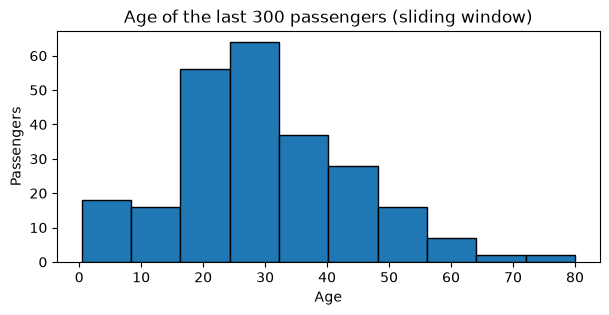

In [5]:
age_fare = X[:, [1, 4]]
stats = StreamingStats(window_size=300)
for chunk in batches(age_fare, CHUNK_SIZE):
    stats.update_stats(chunk)

print("Streaming mean     (age, fare):", np.round(stats.mean(), 3))
print("np.nanmean         (age, fare):", np.round(np.nanmean(age_fare, axis=0), 3))
print("Streaming std      (age, fare):", np.round(stats.std(), 3))
print("Median of last 300 (age, fare):", np.round(stats.quantile(0.5), 3))

counts, edges = stats.histogram(feature=0, bins=10)
plt.figure(figsize=(7, 3))
plt.bar(edges[:-1], counts, width=np.diff(edges), align="edge", edgecolor="black")
plt.title("Age of the last 300 passengers (sliding window)")
plt.xlabel("Age")
plt.ylabel("Passengers")
plt.show()

## 3. Train the pipeline on the stream

Each chunk is first **scored** (by a model that has not seen it) and then used for **training** (`process_chunk`).
The tree only collects chunks in its buffer; once `buffer_size` samples are buffered it retrains on them and clears the buffer.
Until the first retrain there is no tree yet, so the accuracy of those chunks is `nan`.

In [6]:
def make_pipeline(buffer_size, max_depth=4):
    return Pipeline([
        ("impute", Imputer()),
        ("scale", StandardScaler()),
        ("model", DecisionTreeClassifier(max_depth=max_depth, buffer_size=buffer_size)),
    ])

pipe = make_pipeline(buffer_size=200)
tree = pipe.named_steps["model"]
trainer = StreamTrainer(pipe, window_size=200, verbose=True)

precision = StreamingPrecision(average="binary")
recall = StreamingRecall(average="binary")
f1 = StreamingF1(average="binary")
auc = StreamingAUC()
matrix = StreamingConfusionMatrix()

for X_chunk, y_chunk in chunks:
    # Probabilities from the current tree, before it learns from this chunk.
    probability = tree.predict_probability(pipe.transform(X_chunk))[:, 1] if tree.fitted else None
    record = trainer.process_chunk(X_chunk, y_chunk)
    if probability is not None:
        y_pred = trainer.last_y_pred
        for metric in (precision, recall, f1, matrix):
            metric.update(y_chunk, y_pred)
        auc.update(y_chunk, probability)

chunk    0 | acc nan | cumulative nan | retrains 0 | memory 2.7 KB
chunk    1 | acc nan | cumulative nan | retrains 0 | memory 5.5 KB
chunk    2 | acc nan | cumulative nan | retrains 0 | memory 8.2 KB
chunk    3 | acc nan | cumulative nan | retrains 1 | memory 1.3 KB
chunk    4 | acc 0.740 | cumulative 0.740 | retrains 1 | memory 4.0 KB
chunk    5 | acc 0.740 | cumulative 0.740 | retrains 1 | memory 6.8 KB
chunk    6 | acc 0.920 | cumulative 0.800 | retrains 1 | memory 9.5 KB
chunk    7 | acc 0.860 | cumulative 0.815 | retrains 2 | memory 1.2 KB
chunk    8 | acc 0.740 | cumulative 0.800 | retrains 2 | memory 3.9 KB
chunk    9 | acc 0.800 | cumulative 0.800 | retrains 2 | memory 6.7 KB
chunk   10 | acc 0.800 | cumulative 0.800 | retrains 2 | memory 9.4 KB
chunk   11 | acc 0.740 | cumulative 0.792 | retrains 3 | memory 1.0 KB
chunk   12 | acc 0.700 | cumulative 0.782 | retrains 3 | memory 3.7 KB
chunk   13 | acc 0.760 | cumulative 0.780 | retrains 3 | memory 6.5 KB
chunk   14 | acc 0.680

In [7]:
print(f"Cumulative accuracy: {trainer.accuracy.result():.3f}")
print(f"Rolling accuracy: {trainer.rolling_accuracy.result():.3f}  (last 200 passengers)")
print(f"Precision (survived): {precision.result():.3f}")
print(f"Recall    (survived): {recall.result():.3f}")
print(f"F1        (survived): {f1.result():.3f}")
print(f"ROC AUC: {auc.result():.3f}")
print(f"Retrains: {tree.n_retrains_}")
print("Confusion matrix (rows = true, columns = predicted):")
print(matrix.result())

Cumulative accuracy: 0.776
Rolling accuracy: 0.765  (last 200 passengers)
Precision (survived): 0.781
Recall    (survived): 0.601
F1        (survived): 0.679
ROC AUC: 0.760
Retrains: 4
Confusion matrix (rows = true, columns = predicted):
[[372  46]
 [109 164]]


In [8]:
print("Last 3 records of the fit log:")
for record in trainer.fit_log[-3:]:
    print(record)

Last 3 records of the fit log:
{'chunk': 15, 'n_samples': 50, 'n_samples_seen': 800, 'fit_seconds': 0.018354100000010476, 'memory_bytes': 1024, 'n_retrains': 4}
{'chunk': 16, 'n_samples': 50, 'n_samples_seen': 850, 'fit_seconds': 0.0007305999999971391, 'memory_bytes': 3824, 'n_retrains': 4}
{'chunk': 17, 'n_samples': 41, 'n_samples_seen': 891, 'fit_seconds': 0.0005530999999905362, 'memory_bytes': 6120, 'n_retrains': 4}


## 4. Visualizing the stream

Each plotting function returns the matplotlib figure; the `;` at the end only stops Jupyter from drawing it again.

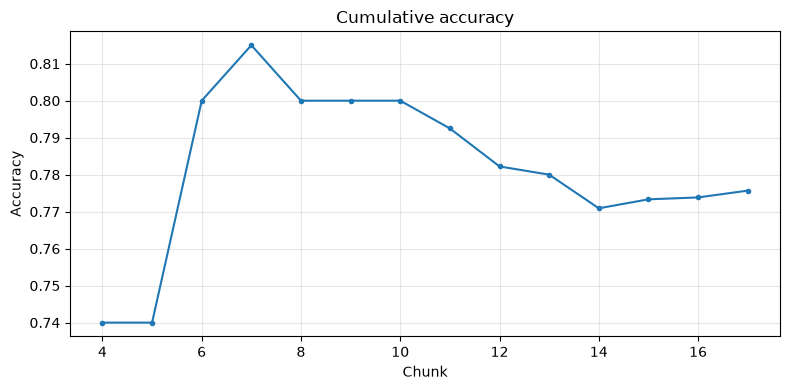

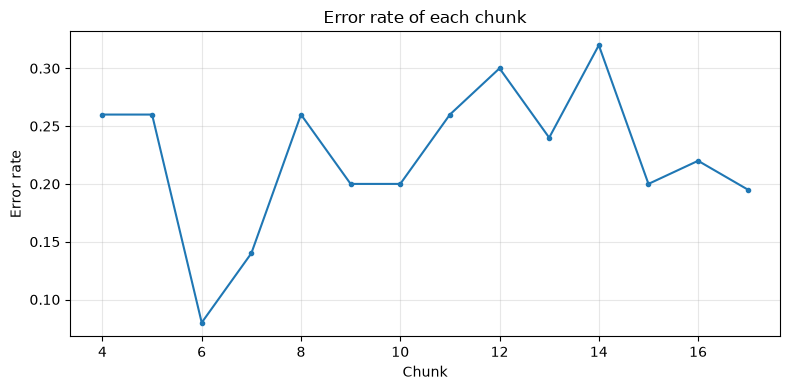

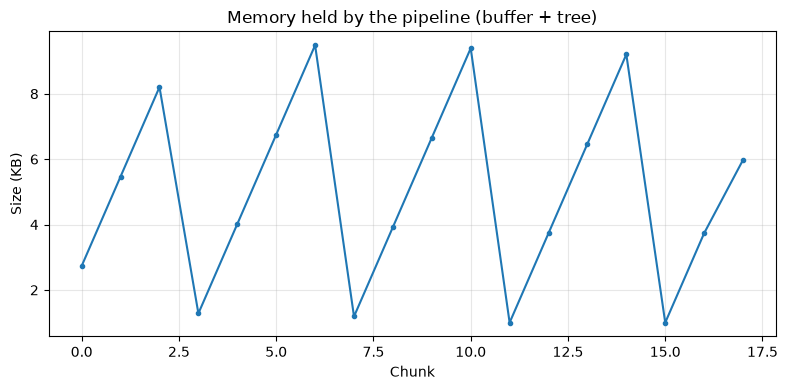

In [9]:
plot_metric_over_time(trainer.history("cumulative_accuracy"),
                      title="Cumulative accuracy", ylabel="Accuracy")
plot_metric_over_time(1 - trainer.history("accuracy"),
                      title="Error rate of each chunk", ylabel="Error rate")
plot_metric_over_time(trainer.history("memory_bytes") / 1024,
                      title="Memory held by the pipeline (buffer + tree)", ylabel="Size (KB)");

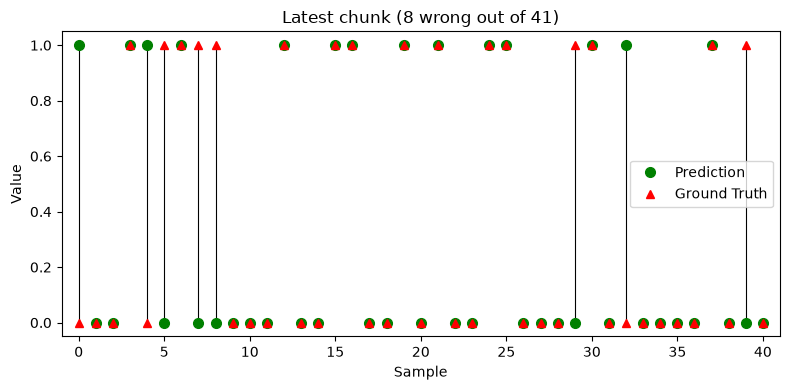

In [10]:
plot_predictions_vs_ground_truth(trainer.last_y_true, trainer.last_y_pred,
                                 title="Latest chunk");

### The trained tree

`plot_tree` draws the most recently trained tree. Thresholds are in **scaled** units, because the tree is trained after the `StandardScaler`.
The left branch answers *yes* to the question in the box.

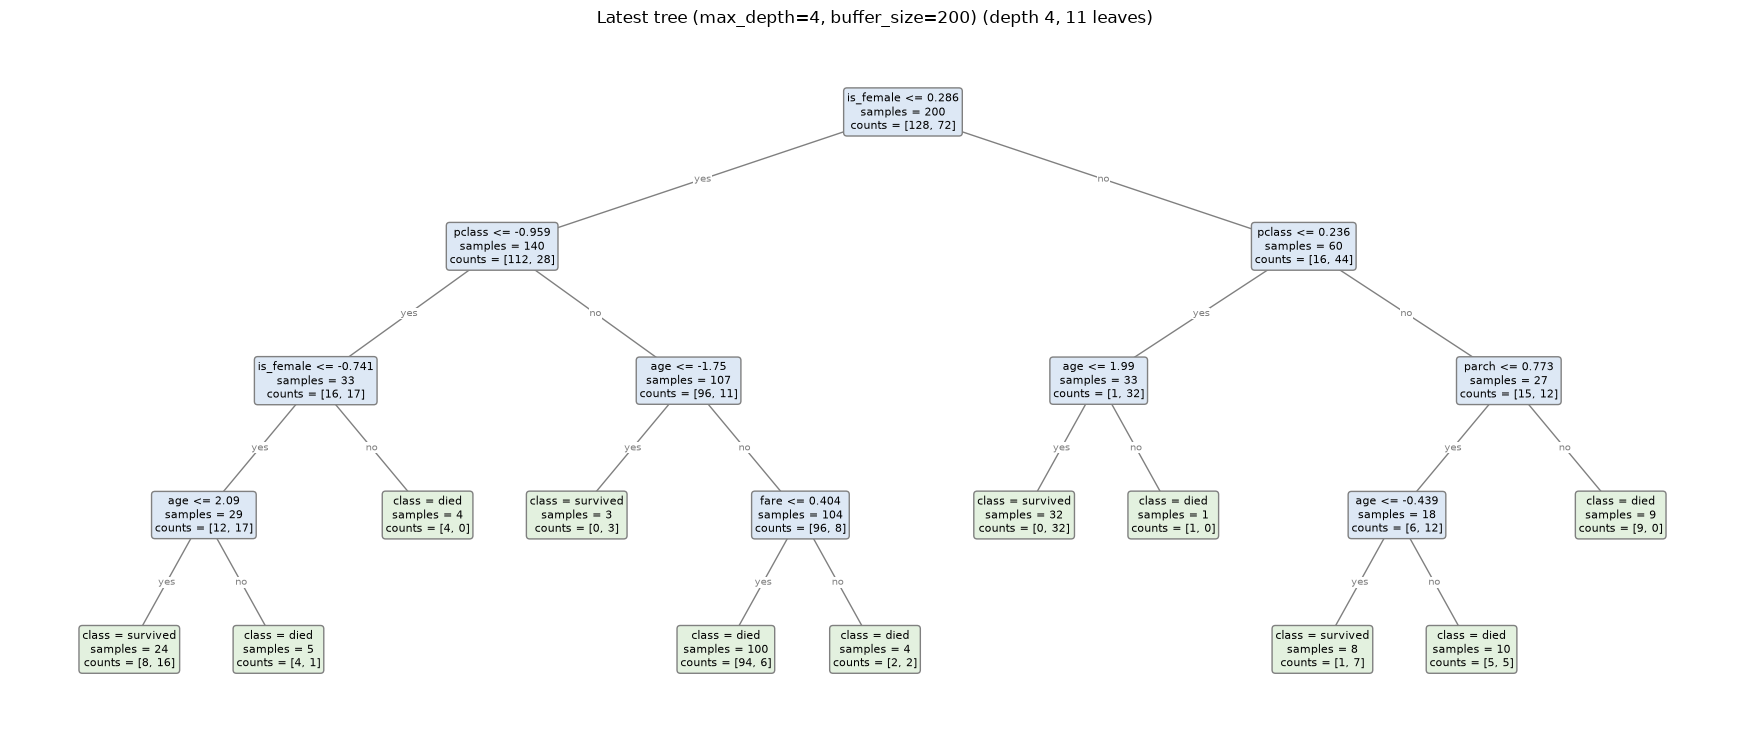

In [11]:
plot_tree(tree, feature_names=feature_names, class_names=class_names,
          title="Latest tree (max_depth=4, buffer_size=200)");

## 5. Effect of `buffer_size`

A small buffer retrains more on little data; a large buffer retrains less on more data.

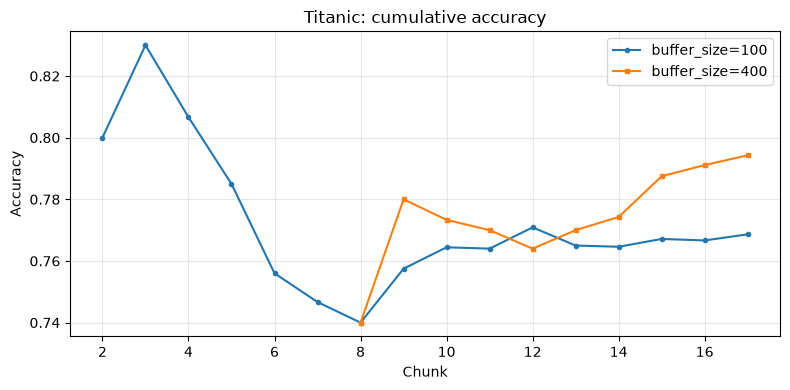

buffer | accuracy | retrains | train time (s)
    50 |    0.756 |       17 |        0.4979
   100 |    0.769 |        8 |        0.1620
   200 |    0.776 |        4 |        0.0658
   400 |    0.794 |        2 |        0.0563


In [12]:
def run_titanic(buffer_size):
    stream_trainer = StreamTrainer(make_pipeline(buffer_size), window_size=200)
    stream_trainer.run(chunks)
    return stream_trainer

small = run_titanic(100)
large = run_titanic(400)
compare_models(small.history("cumulative_accuracy"), large.history("cumulative_accuracy"),
               labels=("buffer_size=100", "buffer_size=400"),
               title="Titanic: cumulative accuracy", ylabel="Accuracy")

print("buffer | accuracy | retrains | train time (s)")
for buffer_size in (50, 100, 200, 400):
    t = run_titanic(buffer_size)
    print(f"{buffer_size:>6} | {t.accuracy.result():>8.3f} | {int(t.history('n_retrains')[-1]):>8} | "
          f"{t.history('fit_seconds').sum():>13.4f}")

The benchmark script runs the same `buffer_size` comparison on a larger synthetic stream (20 000 samples):

In [13]:
from benchmark.benchmark import (format_buffer_table, make_stream, run_buffer_benchmark,
                                 run_loop_benchmark)
from numcompute_stream.benchmarking import format_table

X_bench, y_bench = make_stream(n_samples=20_000)
rows, _ = run_buffer_benchmark(X_bench, y_bench, buffer_sizes=(100, 500, 2000))
print(format_buffer_table(rows))

buffer | accuracy | last 1000 acc | retrains | train (s) | s / retrain
----------------------------------------------------------------------
   100 |   0.7268 |        0.7120 |      200 |    3.2032 |     0.01602
   500 |   0.7766 |        0.7840 |       40 |    1.4992 |     0.03748
  2000 |   0.7487 |        0.8190 |       10 |    0.7828 |     0.07828


## 6. Python loops vs NumPy vectorisation

`run_loop_benchmark` (from `benchmark/benchmark.py`) checks that each loop function gives the same answer as its vectorised version, then times both:

| Calculation | Formula |
|---|---|
| Pairwise distance | $D_{ij} = \sqrt{\sum_k (a_{ik} - b_{jk})^2}$ |
| Gini impurity | $G = 1 - \sum_k p_k^2$ |
| Best split threshold | $\min_t \; (n_L G_L + n_R G_R) / n$ |
| Running mean / variance | Welford: $\bar x_n = \bar x_{n-1} + (x - \bar x_{n-1})/n$ |
| Confusion matrix | $M_{ij} = \#\{\text{true}=i, \text{pred}=j\}$ |

In [14]:
results = run_loop_benchmark(repeats=3, warmup=1)
names, speedups = [], []
for name, result in results.items():
    speedup = result["Python loop"]["median_seconds"] / result["NumPy vectorised"]["median_seconds"]
    names.append(name.split(" (")[0])
    speedups.append(speedup)
    print(name)
    print(format_table(result).split("\nEnvironment")[0])
    print(f"speedup: {speedup:.1f}x\n")

pairwise distance (200 x 150, d=10)
Implementation   | Median (s) | Minimum (s)
-------------------------------------------
Python loop      | 0.0898921 | 0.0724313
NumPy vectorised | 0.0038189 | 0.0037112
speedup: 23.5x

Gini impurity (20000 rows x 5 classes)
Implementation   | Median (s) | Minimum (s)
-------------------------------------------
Python loop      | 0.0353045 | 0.0349489
NumPy vectorised | 0.0012382 | 0.0011294
speedup: 28.5x

best split threshold (5000 samples)
Implementation   | Median (s) | Minimum (s)
-------------------------------------------
Python loop      | 0.0167389 | 0.0161401
NumPy vectorised | 0.0009879 | 0.0009409
speedup: 16.9x

running mean/variance (20000 x 8)
Implementation   | Median (s) | Minimum (s)
-------------------------------------------
Python loop      | 0.087644 | 0.0826206
NumPy vectorised | 0.0054123 | 0.0053973
speedup: 16.2x

confusion matrix (100000 labels, 5 classes)
Implementation   | Median (s) | Minimum (s)
------------------------

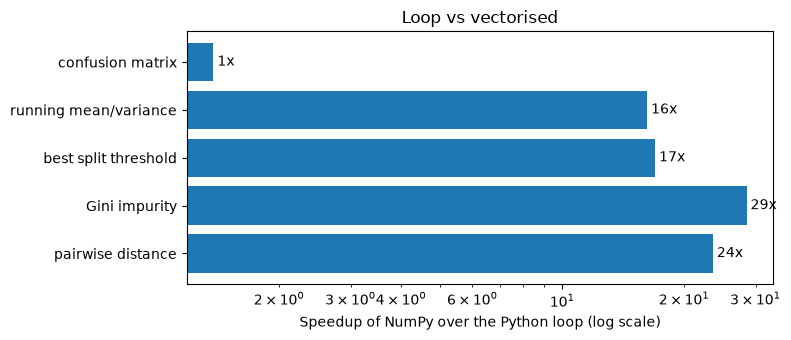

In [15]:
plt.figure(figsize=(8, 3.5))
plt.barh(names, speedups, color="tab:blue")
plt.xscale("log")
plt.xlabel("Speedup of NumPy over the Python loop (log scale)")
plt.title("Loop vs vectorised")
for i, value in enumerate(speedups):
    plt.text(value, i, f" {value:.0f}x", va="center")
plt.tight_layout()
plt.show()